<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 2: A* Search with Admissible Heuristics</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.2 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Implement A* search with admissible heuristics for the 8-puzzle (misplaced tiles, Manhattan distance) and for a grid shortest-route problem, and compare with uniform-cost search.</div>

## 📘 Theory

A* expands the node with the smallest $f(n)=g(n)+h(n)$. If $h$ is **admissible** ($h\le h^*$) tree-A* is optimal; if $h$ is **consistent** graph-A* is optimal.
For the 8-puzzle, $h_1$ = misplaced tiles and $h_2$ = Manhattan distance; $h_2$ dominates $h_1$, so it expands fewer nodes. With $h=0$, A* reduces to uniform-cost search.

## 🧭 Algorithm

1. Insert start with g = 0 and f = h(start) into a priority queue.
2. Pop the node with the lowest f; if it is the goal, return the path.
3. For each successor compute g' = g + step cost; if g' improves the best known g, record parent and push with f = g' + h.
4. Repeat until goal popped or queue empty.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
import heapq, itertools, time
GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)
def succ8(s):
    i = s.index(0); r, c = divmod(i, 3)
    for a, dr, dc in (("Up", -1, 0), ("Down", 1, 0), ("Left", 0, -1), ("Right", 0, 1)):
        nr, nc = r + dr, c + dc
        if 0 <= nr < 3 and 0 <= nc < 3:
            j = nr * 3 + nc; t = list(s); t[i], t[j] = t[j], t[i]; yield a, tuple(t), 1

def h0(s): return 0
def h1(s): return sum(1 for k, v in enumerate(s) if v and v != GOAL8[k])
def h2(s):
    d = 0
    for k, v in enumerate(s):
        if v: gr, gc = divmod(v - 1, 3); r, c = divmod(k, 3); d += abs(r - gr) + abs(c - gc)
    return d

def astar(start, succ, goal, h):
    tie = itertools.count(); frontier = [(h(start), next(tie), start)]
    g = {start: 0}; parent = {start: None}; expanded = 0
    while frontier:
        f, _, s = heapq.heappop(frontier)
        if f > g[s] + h(s): continue
        expanded += 1
        if goal(s):
            path = [s]
            while parent[path[-1]]: path.append(parent[path[-1]][0])
            return path[::-1], g[s], expanded
        for a, n, c in succ(s):
            ng = g[s] + c
            if ng < g.get(n, float("inf")):
                g[n] = ng; parent[n] = (s, a); heapq.heappush(frontier, (ng + h(n), next(tie), n))
    return None, None, expanded

start = (7, 2, 4, 5, 0, 6, 8, 3, 1)   # Russell & Norvig Fig. 3.25 start state
print("h1(start) =", h1(start), "  h2(start) =", h2(start))

h1(start) = 6   h2(start) = 14


In [3]:
import pandas as pd
res = []
for name, h in (("UCS (h=0)", h0), ("A* h1 misplaced", h1), ("A* h2 Manhattan", h2)):
    t = time.time(); path, cost, exp = astar(start, succ8, lambda s: s == GOAL8, h)
    res.append([name, cost, exp, round(time.time() - t, 2)])
df = pd.DataFrame(res, columns=["Algorithm", "Solution cost", "Nodes expanded", "Time (s)"])
print(df.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.barh(df["Algorithm"], df["Nodes expanded"], color=[SLATE, GOLD, NAVY]); ax.set_xscale("log")
for i, v in enumerate(df["Nodes expanded"]): ax.text(v, i, f"  {v:,}", va="center", color=NAVY)
ax.set_title("Nodes expanded (log scale) — better heuristic, less work"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(f"{FIG}/exp02_heuristics.png", dpi=130); plt.show()

      Algorithm  Solution cost  Nodes expanded  Time (s)
      UCS (h=0)             20           55409      0.24
A* h1 misplaced             20            3667      0.02
A* h2 Manhattan             20             283      0.00


### Shortest route on a grid map with obstacles — animated A*

A*  : expanded 134 cells, path length 38
UCS : expanded 287 cells, path length 38


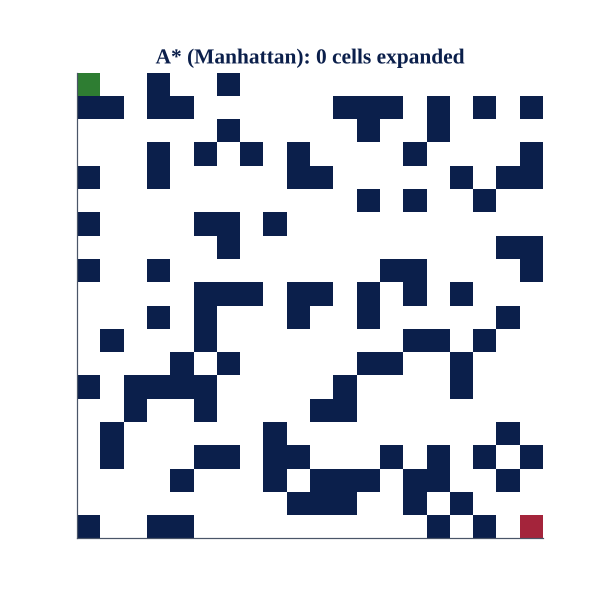

In [4]:
rng = np.random.default_rng(7)
N = 20; grid = (rng.random((N, N)) < 0.25).astype(int)
S, T = (0, 0), (N - 1, N - 1); grid[S] = grid[T] = 0
def gsucc(p):
    for dr, dc in ((1,0),(-1,0),(0,1),(0,-1)):
        r, c = p[0] + dr, p[1] + dc
        if 0 <= r < N and 0 <= c < N and not grid[r, c]: yield "m", (r, c), 1
def manh(p): return abs(p[0] - T[0]) + abs(p[1] - T[1])

def astar_trace(h):
    tie = itertools.count(); fr = [(h(S), next(tie), S)]; g = {S: 0}; par = {S: None}; closed = []
    while fr:
        f, _, s = heapq.heappop(fr)
        if s in closed: continue
        closed.append(s)
        if s == T: break
        for _, n, c in gsucc(s):
            if g[s] + c < g.get(n, 1e9): g[n] = g[s] + c; par[n] = s; heapq.heappush(fr, (g[n] + h(n), next(tie), n))
    path = [T]
    while par.get(path[-1]): path.append(par[path[-1]])
    return closed, path[::-1]
closed_a, path_a = astar_trace(manh)
closed_u, path_u = astar_trace(lambda p: 0)
print(f"A*  : expanded {len(closed_a)} cells, path length {len(path_a)-1}")
print(f"UCS : expanded {len(closed_u)} cells, path length {len(path_u)-1}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
step = max(1, len(closed_a) // 30)
frames = list(range(0, len(closed_a), step)) + [len(closed_a)] * 4
def draw(k):
    ax.clear(); img = np.ones((N, N, 3))
    img[grid == 1] = matplotlib.colors.to_rgb(NAVY)
    for (r, c) in closed_a[:k]: img[r, c] = matplotlib.colors.to_rgb(GOLDL)
    if k >= len(closed_a):
        for (r, c) in path_a: img[r, c] = matplotlib.colors.to_rgb(GOLD)
    img[S] = matplotlib.colors.to_rgb(LEAF); img[T] = matplotlib.colors.to_rgb(CRIMSON)
    ax.imshow(img); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"A* (Manhattan): {min(k, len(closed_a))} cells expanded")
gif = save_gif(animation.FuncAnimation(fig, draw, frames=frames), "exp02_astar_grid.gif", fps=4)
display(Image(filename=gif))

## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>All three searches return the optimal 20-move 8-puzzle solution, but A* with Manhattan distance expands orders of magnitude fewer nodes than UCS. On the grid, A* explores far fewer cells than UCS while returning a path of the same optimal length.</div>

## 🎤 Viva Questions

1. Prove that the Manhattan distance heuristic is admissible.
2. What is meant by one heuristic dominating another?
3. When does A* become uniform-cost search?
4. What happens to A* if the heuristic overestimates?
5. Define consistency and explain why it implies admissibility.